![Banner](../../../../Images/Banner/07_remote_sensing/09_06_banner_rs_lidar.png)


# LiDAR Processing: Quality Control, Cleaning, Ground Classification and Surface Models

A delivered point cloud is raw material. Before it can give terrain, canopy or building products it has to be checked for coverage and consistency, cleaned of noise, reduced to the points that matter, and split into ground and non-ground points. This notebook walks through those steps with `geolattice.rsense.lidar` on a forested site in Mississippi and on the University at Buffalo campus, validates three ground filters against the producers' labels, and builds the three standard surfaces: the digital elevation model (DEM), the digital surface model (DSM) and the canopy height model (CHM).


## Overview

Every LiDAR product depends on a chain of processing steps, and errors early in the chain propagate into everything that follows:

| Step | Question it answers | Typical tools |
|---|---|---|
| Quality control | Is the coverage complete and dense enough? Do overlapping flight lines agree? Are the units and classes what the metadata say? | Density maps, swath-overlap differences, class and return tables |
| Noise removal | Which points are birds, multipath echoes or sensor artefacts? | Statistical and radius outlier filters, elevation bands |
| Selection and thinning | Which points are needed for this product, and how many? | Class, return and polygon filters; voxel or grid thinning |
| Ground classification | Which points lie on the bare earth? | Morphological filters (PMF, SMRF), cloth simulation (CSF), TIN densification, machine learning |
| Surface models | What are the terrain, the top surface and the height of objects above the terrain? | Gridding with min/max/mean statistics, gap filling, DSM minus DEM |
| Accuracy assessment | How close is the DEM to surveyed ground truth? | Checkpoints, RMSEz, NVA and VVA (ASPRS 2014) |


### Quality control

**Point density.** Specifications such as the USGS 3DEP Lidar Base Specification set a minimum aggregate nominal pulse density (for example 2 pulses/m² for quality level QL2) and require that most of the area meets it. A density grid of first returns (one per pulse) shows gaps caused by water, dark roofs, missed flight lines or steep scan angles.

**Swath overlap.** Neighbouring flight lines overlap, so the same ground is measured twice from different positions. On hard, flat surfaces both lines should agree to a few centimetres. Systematic differences reveal errors in the trajectory or the boresight calibration (strip misalignment). Each point's `point_source_id` records the flight line it came from.

**Classes and returns.** A table of class codes and of returns per pulse is a quick check that the data match the metadata: a vegetated area with almost no multiple returns, or a missing ground class, signals a problem.


### Noise

Noise points are far above or below the true surface: birds, low clouds, multipath echoes from water or glass, and range errors near strong reflectors. Two classic filters, both from the Point Cloud Library (PCL):

- **Statistical outlier removal (SOR).** For every point compute the mean distance $\bar d_i$ to its $k$ nearest neighbours. Points with $\bar d_i > \mu + \alpha\,\sigma$ (mean and standard deviation over all points) are outliers.
- **Radius outlier removal.** A point with fewer than $m$ neighbours within radius $r$ is isolated and removed.

Outliers can be dropped or reclassified as low noise (class 7) or high noise (class 18) so they stay in the file but are ignored downstream.


### Ground classification

Separating ground from non-ground points is the hinge on which every terrain and height product turns. The main families of filters:

- **Morphological filters.** Grid the lowest point per cell and apply a morphological *opening* (erosion followed by dilation) with a growing window. An opening removes objects narrower than the window, so the opened surface approximates the terrain; cells that rise above it by more than a slope-dependent threshold are objects. The **Progressive Morphological Filter** (PMF, Zhang et al. 2003) grows the window and the height threshold together. The **Simple Morphological Filter** (SMRF, Pingel et al. 2013) uses disk-shaped windows up to a maximum radius and a threshold of `slope × radius`, then interpolates a provisional terrain and labels points within a small tolerance of it as ground. The window must exceed the largest object (the widest roof); the slope must allow for the steepest terrain.
- **Cloth Simulation Filter** (CSF, Zhang et al. 2016). Turn the point cloud upside down and drop a cloth of connected particles onto it under gravity. Stiff springs (high `rigidness`) keep the cloth flat, so it rests on the lowest points and bridges over buildings and trees (now pointing downwards); soft springs let it follow steep terrain. Points close to the settled cloth are ground.
- **TIN densification** (Axelsson 2000), used in commercial software: start from the lowest points in large cells, build a triangulated surface and add points whose distance and angle to the triangles are small enough.
- **Machine learning and deep learning** classify ground with features of each point and its neighbourhood (see the point classification notebook).

All filters struggle in the same two places: **steep slopes and banks**, where the terrain itself looks like an object, and **dense low vegetation**, where few pulses reach the ground and the lowest return is a few decimetres up.


### Surface models

A point cloud becomes a raster by binning points into cells and reducing each cell with a statistic:

- **DEM (DTM).** Ground points only, mean or minimum elevation per cell. Cells without ground points (under dense canopy, buildings and water) are filled by interpolation: nearest neighbour, inverse distance weighting (IDW) or linear interpolation on a Delaunay triangulation (a TIN).
- **DSM.** The highest first return per cell: canopy tops and roofs. Empty cells are filled the same way.
- **CHM** (or normalised DSM, nDSM). $\text{CHM} = \text{DSM} - \text{DEM}$, the height of objects above the ground. Small "pits" (single cells where a pulse went deep into a crown) are removed with a median filter.

The cell size should not be smaller than the point spacing ($1/\sqrt{\rho}$) for a DSM, and noticeably larger for a DEM under canopy, where ground points are sparse.

**Vertical accuracy.** ASPRS (2014) reports the **non-vegetated vertical accuracy** $\text{NVA}_{95} = 1.96 \times \text{RMSE}_z$ on open hard surfaces, assuming normally distributed errors, and the vegetated vertical accuracy (VVA) as the 95th percentile of absolute errors under vegetation.


## Processing LiDAR Point Clouds with GeoLattice


### Learning objectives

1. Check point density against quality-level thresholds and measure the agreement of overlapping flight lines.
2. Detect and remove noise with statistical and radius outlier filters.
3. Select points by class, return, box and polygon, and thin a cloud with voxel and grid methods.
4. Classify ground with SMRF, CSF and PMF, validate them against reference labels and tune their parameters.
5. Build a DEM, DSM and CHM, compare gap-filling methods and choose a cell size.
6. Assess vertical accuracy with checkpoints and export rasters and classified point clouds.


### Data

| File | Content |
|---|---|
| `madison_utm.laz` | Madison, Mississippi: 4.07 million classified airborne LiDAR points in UTM zone 15N metres (written by the fundamentals notebook from `madison.copc.laz`) |
| `UB/20080417_10901090_ld_p28.laz`, `UB/20080417_10951090_ld_p28.laz` | Two neighbouring 2008 tiles of the University at Buffalo North Campus, New York (LAS 1.0, geographic NAD83), with ground (2), unclassified (1), low noise (7) and overlap (12) points |


### Contents

1. Setup
2. Loading and preparing the two sites
3. Quality control: density, flight lines and swath overlap
4. Noise and outliers
5. Selecting points: classes, returns, boxes and polygons
6. Thinning
7. Ground classification with SMRF, CSF and PMF
8. Tuning the ground filters
9. DEM, DSM and CHM
10. Gap filling and cell size
11. Vertical accuracy with checkpoints
12. Exporting the products
13. Summary and exercises


## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings

import time  # timing
import numpy as np  # arrays
import pandas as pd  # tables
import geopandas as gpd  # vector data (polygons, checkpoints)
import rasterio  # raster I/O
import matplotlib.pyplot as plt  # figures
from shapely.geometry import Point  # simple geometries

import geolattice.rsense as rs  # GeoLattice remote sensing
from geolattice.rsense.core import ASPRS_CLASSES  # ASPRS class code -> name

rasterio.Env(CPL_LOG="/dev/null").__enter__()  # silence GDAL log messages
plt.rcParams.update({"figure.dpi": 110})  # figure resolution
print("geolattice.rsense", rs.__version__, "| backend:", rs.set_backend("cpu"))  # version and array backend

geolattice.rsense 0.3.35 | backend: cpu


In [2]:
from pathlib import Path  # file paths

# The notebook's data folder: ../../../../Data/08_remote_sensing/08_06_lidar/ next to this notebook, found from here or from the repository root.
DATA = next((p for p in (Path("Data/08_remote_sensing/08_06_lidar"), Path("../../../../Data/08_remote_sensing/08_06_lidar"))
             if p.is_dir()), None)
if DATA is None:  # neither location exists
    # stop with a clear message
    raise FileNotFoundError("Run the notebook from its own folder or from the GeoLattice repository root.")
OUT = DATA.parent / "outputs"  # folder for the products this notebook writes
OUT.mkdir(exist_ok=True)  # create it if needed

MADISON_UTM = DATA / "madison_utm.laz"  # metric Madison cloud from the fundamentals notebook
if not MADISON_UTM.exists():  # not written yet: build it from the COPC file
    ft = rs.lidar.read_las(DATA / "madison.copc.laz")  # feet, state plane
    xy = rs.lidar.reproject(ft, 32615)  # x and y to UTM 15N
    # write the metric cloud (z feet -> metres)
    rs.lidar.write_las(rs.PointCloud(xy.x, xy.y, np.asarray(ft.z) * 0.3048006096, dict(xy.attrs), 32615),
                       MADISON_UTM)  # with z converted to metres
UB_TILES = [DATA / "UB" / "20080417_10901090_ld_p28.laz", DATA / "UB" / "20080417_10951090_ld_p28.laz"]  # two tiles

## Loading and preparing the two sites

**Madison** is read in metres and cropped to an 800 m square of mixed forest, roads and water in the south-west of the survey. **UB** is two neighbouring tiles merged with `rs.lidar.merge_pointclouds`, reprojected from geographic NAD83 to NAD83 / UTM zone 17N (EPSG:26917) and cropped to a 1 km square around the centre of the campus, which keeps the ground-filter experiments below to a few minutes.


In [3]:
madison = rs.lidar.read_las(MADISON_UTM)  # whole Madison cloud (UTM 15N, metres)
mx0, my0 = madison.bbox[:2]  # south-west corner
mad = madison.crop(mx0, my0, mx0 + 800, my0 + 800)  # an 800 m x 800 m forested block
ub = rs.lidar.reproject(rs.lidar.merge_pointclouds([rs.lidar.read_las(p) for p in UB_TILES]), 26917)  # 2 tiles, metres
ucx, ucy = np.mean(ub.bbox[::2]), np.mean(ub.bbox[1::2])  # centre of the two tiles
ub = ub.crop(ucx - 500, ucy - 500, ucx + 500, ucy + 500)  # a 1 km x 1 km block of the campus
for name, pc in (("Madison", mad), ("UB", ub)):  # the two sites
    print(f"{name}: {pc}")  # count, fields, bbox and CRS

Madison: <PointCloud 1,045,588 pts [CPU] fields=['x', 'y', 'z', 'intensity', 'return_number', 'number_of_returns', 'classification', 'scan_angle', 'gps_time', 'user_data', 'point_source_id'] bbox=(767845.4, 3594643.5, 768623.1, 3595443.5) crs=32615>
UB: <PointCloud 1,028,921 pts [CPU] fields=['x', 'y', 'z', 'classification', 'gps_time', 'intensity', 'number_of_returns', 'point_source_id', 'return_number', 'scan_angle_rank', 'user_data'] bbox=(680249.5, 4762506.3, 681249.5, 4763506.3) crs=26917>


## Quality control: density, flight lines and swath overlap

`rs.lidar.summary` gives the point count, area, density and spacing. `rs.lidar.density_map` with `first_returns=True` counts pulses per m², the quantity that specifications regulate.


In [4]:
qc = {}  # one column per site
for name, pc in (("Madison", mad), ("UB", ub)):  # the two sites
    s = rs.lidar.summary(pc)  # summary dictionary
    qc[name] = {"points": s["points"], "area (km²)": s["area_m2"] / 1e6,  # size
                "points/m²": s["density_pts_m2"], "spacing (m)": s["spacing_m"],  # density and spacing
                "pulses/m²": len(pc.first_returns()) / s["area_m2"],  # first returns per m²
                "multi-return pulses (%)": 100 * np.mean(pc.first_returns()["number_of_returns"] > 1),  # canopy signal
                "flight lines": len(np.unique(pc["point_source_id"]))}  # distinct point_source_id values
pd.DataFrame(qc).round(2)  # show the table

,Madison,UB
points,1045588.00,1028921.00
area (km²),0.62,1.00
points/m²,1.68,1.03
spacing (m),0.77,0.99
pulses/m²,1.03,1.02
multi-return pulses (%),42.46,1.06
flight lines,2.00,2.00


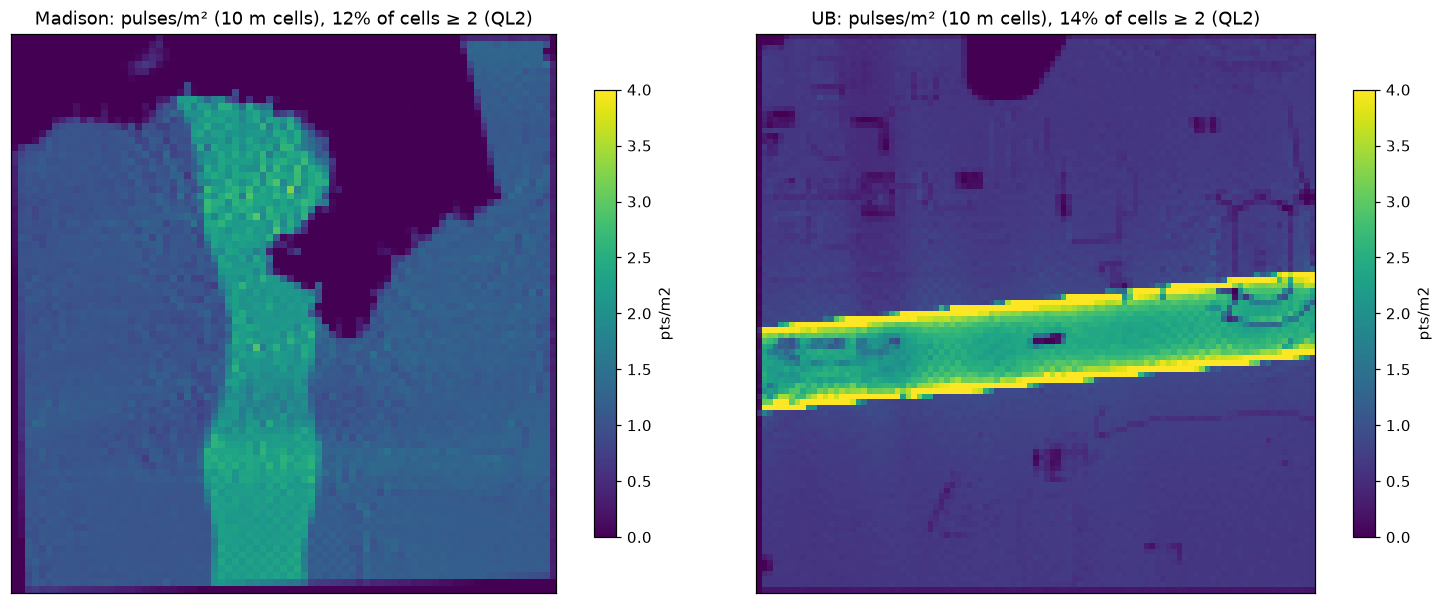

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))  # two panels
for ax, (name, pc) in zip(axes, (("Madison", mad), ("UB", ub))):  # the two sites
    d = rs.lidar.density_map(pc, 10.0, first_returns=True)  # pulses per m² in 10 m cells
    share = float((d >= 2).sum() / d.notnull().sum())  # share of cells meeting QL2
    rs.viz.plot_raster(d, ax=ax, cmap="viridis", vmin=0, vmax=4,  # the map
                       title=f"{name}: pulses/m² (10 m cells), {share:.0%} of cells ≥ 2 (QL2)")
    ax.set_xticks([]); ax.set_yticks([])  # no ticks
plt.tight_layout(); plt.show()  # draw

Neither survey reaches the QL2 pulse density: both were flown with about 1 pulse/m², typical of surveys of their time and enough for a 1 to 2 m DEM. Density doubles where flight lines overlap (the bright stripes) and drops to zero over water and some dark roofs. The table also shows a striking difference in return structure: 42 % of Madison's pulses produced several returns (leaf-on forest), but only 1 % of UB's. The 2008 UB system recorded almost exclusively single returns, so return-based rules (for example "trees give multiple returns") cannot be used on these data.

**Flight lines.** Colouring points by `point_source_id` shows the individual swaths and where they overlap.


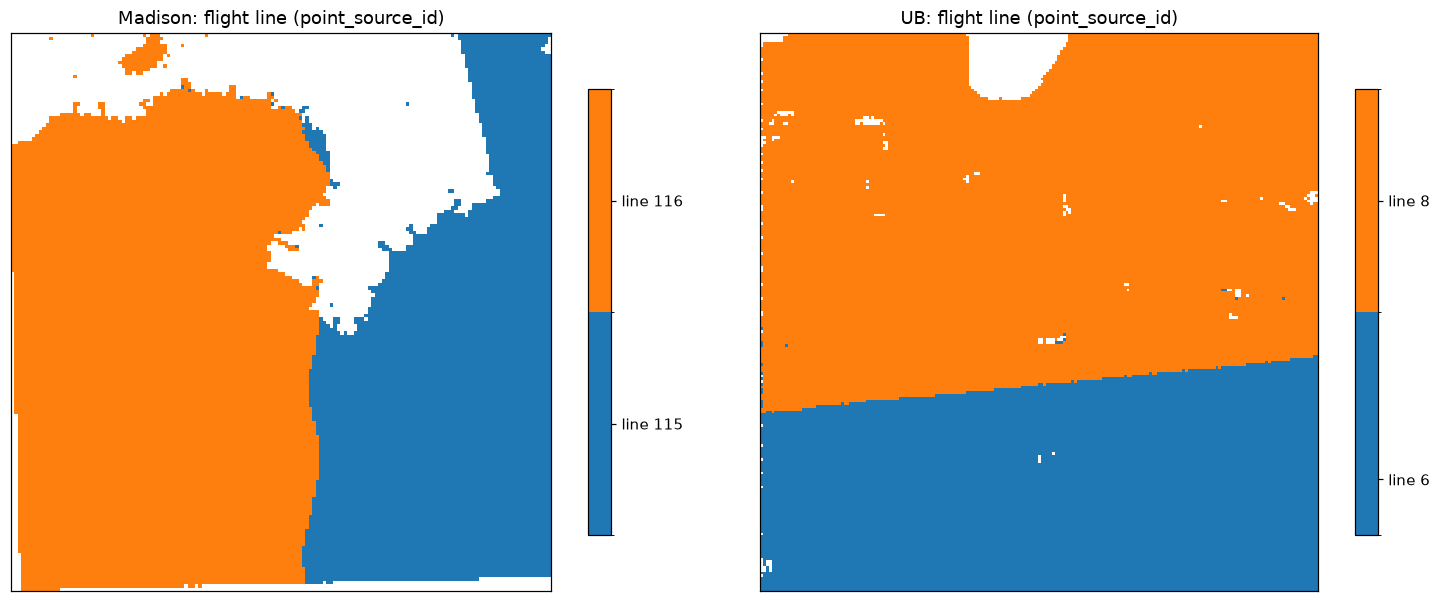

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))  # two panels
for ax, (name, pc) in zip(axes, (("Madison", mad), ("UB", ub))):  # the two sites
    line = rs.lidar.rasterize(pc, 5.0, value="point_source_id", stat="max")  # highest line id per 5 m cell
    ids = np.unique(line.values[np.isfinite(line.values)]).astype(int)  # flight lines present
    rs.viz.plot_raster(line, ax=ax, title=f"{name}: flight line (point_source_id)",  # map of lines
                       categorical={k: (f"line {k}", plt.cm.tab10(i % 10)) for i, k in enumerate(ids)})
    ax.set_xticks([]); ax.set_yticks([])  # no ticks
plt.tight_layout(); plt.show()  # draw

**Swath overlap.** `rs.lidar.swath_overlap` compares, in every cell measured by two or more flight lines, the lowest point of each line and reports the largest difference `dz`. On UB, the overlap points of the second line were labelled class 12, so the test uses ground (2) and overlap (12) points; on bare, flat ground both lines should agree to about 10 cm.


cells measured by ≥ 2 lines: 31,831 | on flat ground: 24,520
flat-ground line-to-line difference: median 1.6 cm, 90th percentile 8.5 cm


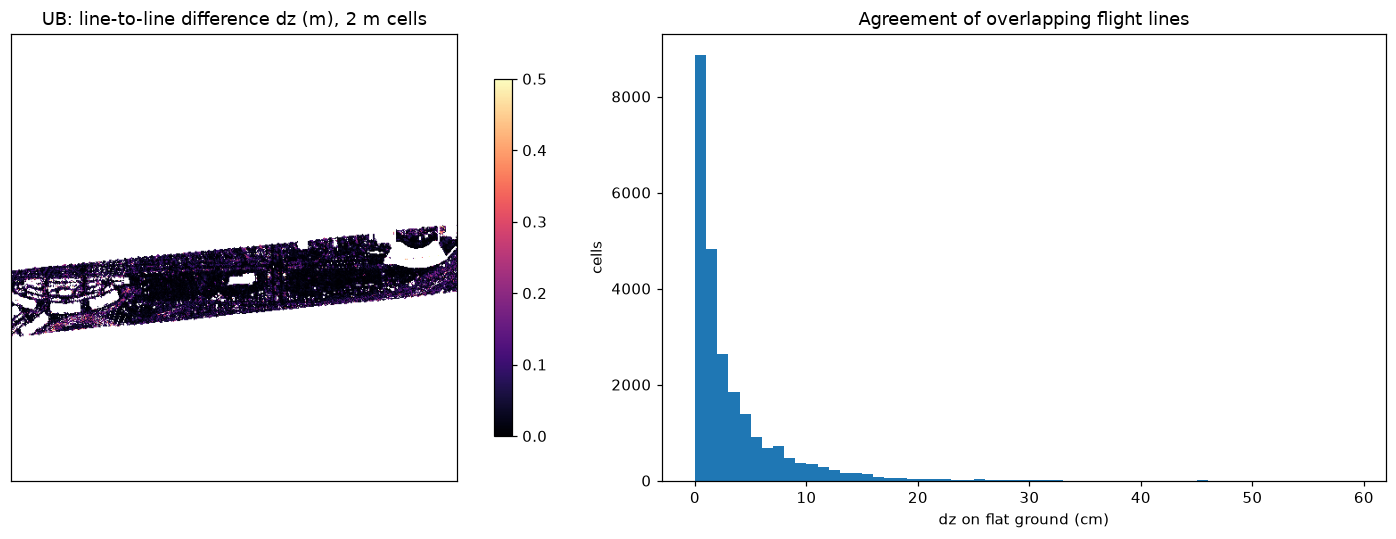

In [7]:
open_ground = ub.by_class(2, 12)  # ground points and overlap points from the second line
sw = rs.lidar.swath_overlap(open_ground, res=2.0, min_points=2)  # inter-line differences in 2 m cells
slope_ub = rs.lidar.slope(rs.lidar.rasterize(ub.by_class(2), 2.0, stat="mean", bounds=open_ground.bbox))  # terrain slope
flat = (slope_ub.values < 5) & np.isfinite(sw["dz"].values)  # flat cells with a difference value
dz = sw["dz"].values[flat]  # differences on flat ground
print(f"cells measured by ≥ 2 lines: {np.isfinite(sw['dz'].values).sum():,} | on flat ground: {flat.sum():,}")  # counts
print(f"flat-ground line-to-line difference: median {np.median(dz) * 100:.1f} cm, "  # summary line
      f"90th percentile {np.percentile(dz, 90) * 100:.1f} cm")  # agreement between flight lines

fig, axes = plt.subplots(1, 2, figsize=(14, 5))  # two panels
rs.viz.plot_raster(sw["dz"].where(sw["dz"] < 1), ax=axes[0], cmap="magma", vmax=0.5,  # map of differences
                   title="UB: line-to-line difference dz (m), 2 m cells")
axes[0].set_xticks([]); axes[0].set_yticks([])  # no ticks
axes[1].hist(dz * 100, bins=np.arange(0, 60, 1), color="C0")  # histogram
axes[1].set(xlabel="dz on flat ground (cm)", ylabel="cells", title="Agreement of overlapping flight lines")  # labels
plt.tight_layout(); plt.show()  # draw

On flat ground the two flight lines agree to a median of under 2 cm, and 90 % of the cells to within about 9 cm, as expected from a well-calibrated survey. The larger differences sit on building edges, kerbs and slopes, where a small horizontal offset produces a large vertical difference. A systematic shift across a whole overlap strip would point to a calibration problem.


## Noise and outliers

A histogram of height above the local ground surface is the quickest way to look for points that do not belong. The cell computes heights from the producer's ground points and then runs both outlier filters with `action="classify"`, which labels suspected noise as class 7 (below the local surface) or 18 (above it) instead of deleting it.


In [8]:
ground_surface = rs.lidar.dem(ub, 2.0)  # provisional terrain from the provider's ground points
ubh = rs.lidar.normalize_heights(ub, ground_surface)  # height above that terrain for every point
h = np.asarray(ubh["height"])  # heights
# summary line
print(f"points more than 40 m above ground: {(h > 40).sum():,} | more than 2 m below: {(h < -2).sum():,} | "
      f"provider low noise (7): {(ub['classification'] == 7).sum():,}")  # suspicious points

t0 = time.perf_counter()  # start the timer
sor = rs.lidar.statistical_outlier_removal(ubh, k=8, std_ratio=3.0, action="classify")  # SOR, flagged as 7 or 18
t_sor = time.perf_counter() - t0  # SOR time
t0 = time.perf_counter()  # restart the timer
ror = rs.lidar.radius_outlier_removal(ubh, radius=3.0, min_neighbors=3, action="classify")  # radius filter
t_ror = time.perf_counter() - t0  # radius filter time

rows = {}  # one row per method
for name, out, sec in (("statistical (k=8, 3σ)", sor, t_sor), ("radius (3 m, 3 neighbours)", ror, t_ror)):  # methods
    c = np.asarray(out["classification"])  # new classes
    new = np.isin(c, (7, 18)) & ~np.isin(ub["classification"], (7, 18))  # newly flagged points
    rows[name] = {"flagged": int(new.sum()), "of which > 40 m up": int((new & (h > 40)).sum()),  # results
                  "high noise (18)": int(((c == 18) & new).sum()), "low noise (7)": int(((c == 7) & new).sum()),
                  "seconds": round(sec, 1)}
pd.DataFrame(rows).T  # show the comparison

points more than 40 m above ground: 604 | more than 2 m below: 1,042 | provider low noise (7): 73


,flagged,of which > 40 m up,high noise (18),low noise (7),seconds
"statistical (k=8, 3σ)",5033.0,22.0,4178.0,855.0,2.1
"radius (3 m, 3 neighbours)",2982.0,9.0,2502.0,480.0,3.5


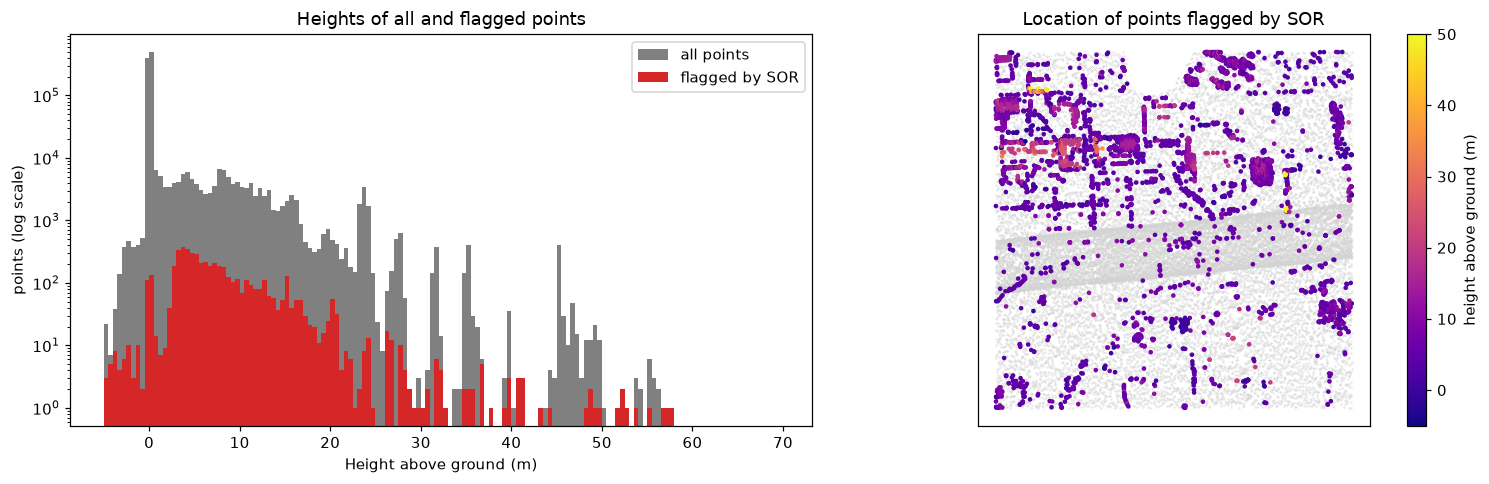

In [9]:
c_sor = np.asarray(sor["classification"])  # classes after SOR
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))  # two panels
axes[0].hist(h, bins=np.arange(-5, 70, 0.5), color="grey", log=True, label="all points")  # all heights
axes[0].hist(h[np.isin(c_sor, (7, 18))], bins=np.arange(-5, 70, 0.5), color="C3", log=True, label="flagged by SOR")  # flagged
axes[0].set(xlabel="Height above ground (m)", ylabel="points (log scale)", title="Heights of all and flagged points")  # labels
axes[0].legend()  # legend
noise = sor.filter(np.isin(c_sor, (7, 18)))  # the flagged points
axes[1].scatter(ub.x[::40], ub.y[::40], s=0.1, c="lightgrey")  # a sample of all points as background
sc = axes[1].scatter(noise.x, noise.y, s=4, c=np.asarray(noise["height"]), cmap="plasma", vmin=-5, vmax=50)  # noise
plt.colorbar(sc, ax=axes[1], label="height above ground (m)")  # colour bar
axes[1].set(title="Location of points flagged by SOR", xticks=[], yticks=[], aspect="equal")  # labels
plt.tight_layout(); plt.show()  # draw

The histogram shows why outlier filters must be checked before they are trusted. The points 40 to 55 m above ground form distinct peaks: they are the roofs of the tallest campus buildings, not birds. SOR flags about 5,000 points, but only 22 of them are above 40 m; most lie on building walls, roof edges, light poles and tree crowns, where a survey with 1 point/m² leaves real points far from their neighbours. At this density a global distance threshold cannot tell sparse but real structures from noise, so the flags are kept as a separate class for review rather than deleted. Outlier filters work much better on dense data (several points per m²), and true noise (birds, low clouds) is usually isolated by tens of metres. For the rest of this notebook only the producer's noise class is removed.


In [10]:
ub = ub.drop_noise()  # drop only the producer's noise class; the SOR flags are kept for review, not applied
mad = mad.drop_noise()  # the same for Madison
print(f"UB after cleaning: {len(ub):,} points | Madison: {len(mad):,} points")  # counts after cleaning

UB after cleaning: 1,028,848 points | Madison: 1,045,512 points


## Selecting points: classes, returns, boxes and polygons

A `PointCloud` supports the usual selections directly (`by_class`, `ground`, `first_returns`, `crop`, `filter` with any boolean mask), and `rs.lidar.clip_polygon` keeps the points inside or outside a shapely geometry or GeoDataFrame. The cell builds a 150 m circle around the centre of the UB tiles and compares how many points each selection keeps.


In [11]:
cx, cy = np.mean(ub.bbox[::2]), np.mean(ub.bbox[1::2])  # centre of the UB area
circle = gpd.GeoDataFrame(geometry=[Point(cx, cy).buffer(150)], crs=26917)  # a 150 m radius polygon
z = ub.z  # elevations
steps = {"all points": ub, "ground (2)": ub.ground(), "unclassified (1)": ub.by_class(1),  # class selections
         "overlap (12)": ub.by_class(12), "first returns": ub.first_returns(),  # return selection
         "last returns": ub.filter(ub["return_number"] == ub["number_of_returns"]),
         "500 m box": ub.crop(cx - 250, cy - 250, cx + 250, cy + 250),  # box
         "inside 150 m circle": rs.lidar.clip_polygon(ub, circle),  # polygon
         "outside 150 m circle": rs.lidar.clip_polygon(ub, circle, invert=True),
         "elevation 1st to 99th percentile": ub.filter((z > np.percentile(z, 1)) & (z < np.percentile(z, 99)))}
pd.DataFrame({"points": {k: len(v) for k, v in steps.items()},  # counts
              "share": {k: round(len(v) / len(ub), 3) for k, v in steps.items()}})  # shares

,points,share
all points,1028848,1.000
ground (2),581330,0.565
unclassified (1),126773,0.123
overlap (12),320745,0.312
first returns,1017979,0.989
last returns,1017896,0.989
500 m box,370352,0.360
inside 150 m circle,148864,0.145
outside 150 m circle,879984,0.855
elevation 1st to 99th percentile,1008259,0.980


## Thinning

Thinning reduces the number of points, either to make density uniform (overlap strips have twice as many points) or to speed up processing. `rs.lidar.thin` offers:

- `voxel`: one point per cube of side `size`, keeping the 3D structure;
- `grid_min` and `grid_max`: the lowest or highest point per 2D cell, a quick ground or surface sample;
- `random`: a random `fraction` of the points.

The table shows how many points each method keeps for Madison and how a 1 m DSM built from the thinned cloud differs from the DSM of the full cloud.


In [12]:
dsm_full = rs.lidar.dsm(mad, 1.0)  # DSM from all points
rows = {}  # one row per method
# thinning settings to compare
for name, kw in (("voxel 0.5 m", dict(size=0.5, method="voxel")), ("voxel 1 m", dict(size=1.0, method="voxel")),
                 ("grid_max 1 m", dict(size=1.0, method="grid_max")), ("grid_min 1 m", dict(size=1.0, method="grid_min")),
                 ("random 25 %", dict(method="random", fraction=0.25))):  # thinning settings
    t0 = time.perf_counter()  # start the timer
    th = rs.lidar.thin(mad, **kw)  # thin the cloud
    sec = time.perf_counter() - t0  # time taken
    d = rs.lidar.dsm(th, 1.0, bounds=mad.bbox).reindex_like(dsm_full, method="nearest") - dsm_full  # DSM difference
    rows[name] = {"points": len(th), "kept": len(th) / len(mad), "seconds": sec,  # size and speed
                  "DSM bias (m)": float(d.mean()), "DSM RMSE (m)": float(np.sqrt((d ** 2).mean()))}  # effect on the DSM
pd.DataFrame(rows).T.round(3)  # show the table

,points,kept,seconds,DSM bias (m),DSM RMSE (m)
voxel 0.5 m,995802.0,0.952,1.069,0.002,0.388
voxel 1 m,814439.0,0.779,1.157,0.022,1.331
grid_max 1 m,446145.0,0.427,0.227,0.259,1.909
grid_min 1 m,446145.0,0.427,0.318,-2.602,5.903
random 25 %,261378.0,0.250,0.021,-0.196,2.912


Voxel thinning at 0.5 m keeps 95 % of the points and changes the DSM least (RMSE about 0.4 m); at 1 m it removes a fifth of the points and the DSM error rises to over 1 m in the canopy. `grid_max` keeps one point per 1 m cell, but its grid starts at the cloud's own corner rather than on the DSM grid, so at crown edges the "highest point" falls into a neighbouring DSM cell and the DSM changes by up to metres: thin on exactly the grid of the product you will build. `grid_min` keeps the lowest point per cell and lowers the DSM by 2.6 m on average, which is why it is a ground sampler, not a general thinning method. Random thinning is the crudest.


## Ground classification with SMRF, CSF and PMF

`rs.lidar.classify_ground(pc, method)` runs `smrf`, `csf` or `pmf` and writes class 2 for ground and 1 for everything else. The reference is the producer's classification, restricted to points whose label is unambiguous:

- Madison: ground (2) against low and medium vegetation (3, 4);
- UB: ground (2) against unclassified (1), which on the campus is mostly buildings and trees. Overlap points (12) carry no ground/non-ground label and are excluded.

Overall accuracy, Cohen's kappa, ground recall (share of true ground found) and ground precision (share of predicted ground that is true ground) summarise each run.


In [13]:
def scores(pred_ground, ref_ground):  # confusion-matrix scores for a binary ground mask
    tp = np.sum(pred_ground & ref_ground); fp = np.sum(pred_ground & ~ref_ground)  # true and false positives
    fn = np.sum(~pred_ground & ref_ground); tn = np.sum(~pred_ground & ~ref_ground)  # false and true negatives
    n = tp + fp + fn + tn  # number of points
    oa = (tp + tn) / n  # overall accuracy
    pe = ((tp + fp) * (tp + fn) + (fn + tn) * (fp + tn)) / n ** 2  # chance agreement
    return {"overall accuracy": oa, "kappa": (oa - pe) / (1 - pe),  # accuracy and kappa
            "ground recall": tp / (tp + fn), "ground precision": tp / (tp + fp)}  # recall and precision

SITES = {"Madison": (mad, (2, 3, 4)), "UB": (ub, (2, 1))}  # cloud and unambiguous reference classes
METHODS = {"SMRF": dict(method="smrf", cell=1.0, slope=0.15, window=18),  # default-like settings
           "CSF": dict(method="csf", resolution=1.0, rigidness=2),
           "PMF": dict(method="pmf", cell=1.0, max_window=33, slope=0.15)}
rows, ground = {}, {}  # scores and classified clouds
for site, (pc, valid_cls) in SITES.items():  # each site
    c = np.asarray(pc["classification"])  # reference classes
    valid, ref = np.isin(c, valid_cls), c == 2  # points with a clear label, reference ground
    for name, kw in METHODS.items():  # each filter
        kw = dict(kw); method = kw.pop("method")  # separate the method name
        t0 = time.perf_counter()  # start the timer
        out = rs.lidar.classify_ground(pc, method, **kw)  # classify ground
        sec = time.perf_counter() - t0  # time taken
        pred = np.asarray(out["classification"]) == 2  # predicted ground
        rows[(site, name)] = {**scores(pred[valid], ref[valid]), "seconds": sec}  # scores
        ground[(site, name)] = out  # keep the classified cloud
pd.DataFrame(rows).T.round(3)  # show the comparison

overall accuracy  kappa  ground recall  ground precision  \
Madison SMRF             0.958  0.916          1.000             0.916   
        CSF              0.956  0.911          1.000             0.912   
        PMF              0.961  0.921          0.998             0.922   
UB      SMRF             0.908  0.608          1.000             0.899   
        CSF              0.914  0.641          0.999             0.906   
        PMF              0.915  0.655          0.993             0.911   

              seconds  
Madison SMRF   10.224  
        CSF    15.227  
        PMF     0.321  
UB      SMRF   22.228  
        CSF    21.497  
        PMF     1.384

All three filters find nearly all true ground points (recall close to 1); they differ in how many non-ground points they wrongly call ground (precision). With default settings all three do well in the Madison forest (kappa about 0.92). On the UB campus kappa drops to about 0.6: buildings wider than the filter window stay in the ground class, as the next sections show. PMF is by far the fastest here because it works on a coarse sequence of square windows.

A cross-section through Madison compares the producer's labels with SMRF's.


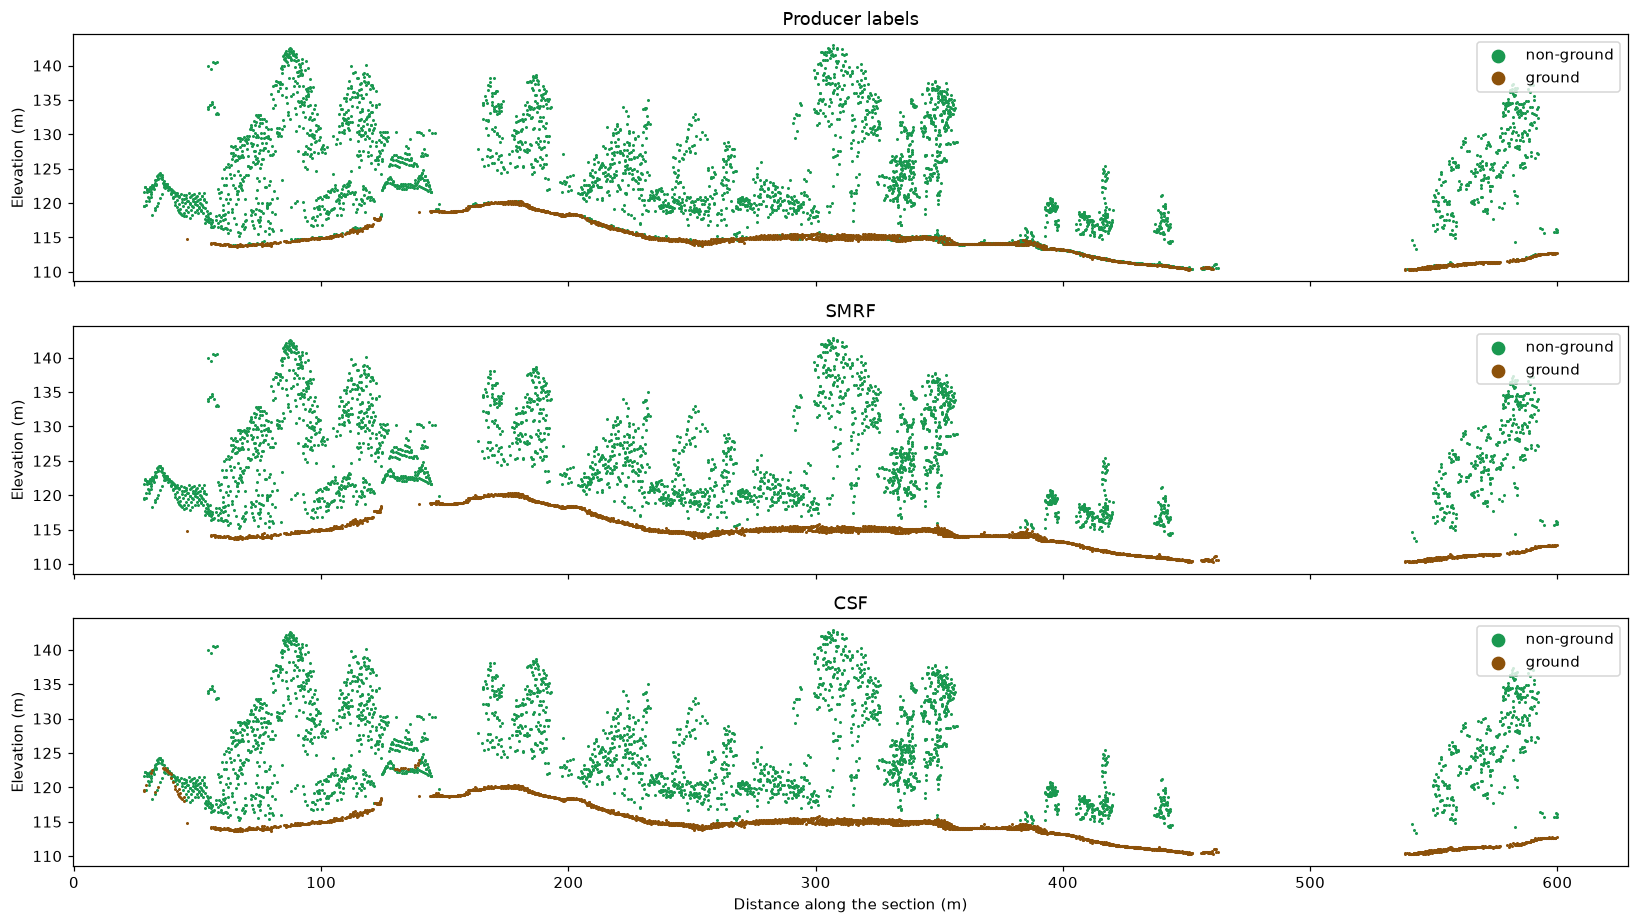

In [14]:
ymid = my0 + 400  # a west-east line through the middle of the Madison block
start, end = (mx0, ymid), (mx0 + 600, ymid)  # 600 m long
fig, axes = plt.subplots(3, 1, figsize=(15, 8.5), sharex=True)  # three panels
for ax, (title, cloud) in zip(axes, (("Producer labels", mad), ("SMRF", ground[("Madison", "SMRF")]),  # clouds
                                     ("CSF", ground[("Madison", "CSF")]))):
    sec = rs.lidar.cross_section(cloud, start, end, width=6)  # 6 m wide slice
    g = np.asarray(sec["classification"]) == 2  # ground points in the slice
    ax.scatter(sec["distance"][~g], sec.z[~g], s=1, color="#1a9850", label="non-ground")  # vegetation etc.
    ax.scatter(sec["distance"][g], sec.z[g], s=1, color="#8c510a", label="ground")  # ground
    ax.set(ylabel="Elevation (m)", title=title); ax.legend(markerscale=8, loc="upper right")  # labels
axes[-1].set_xlabel("Distance along the section (m)"); plt.tight_layout(); plt.show()  # draw

**Where do the filters disagree with the producer?** Mapping the disagreement per 5 m cell shows that the errors concentrate along stream banks and road embankments (steep terrain) and in low, dense vegetation.


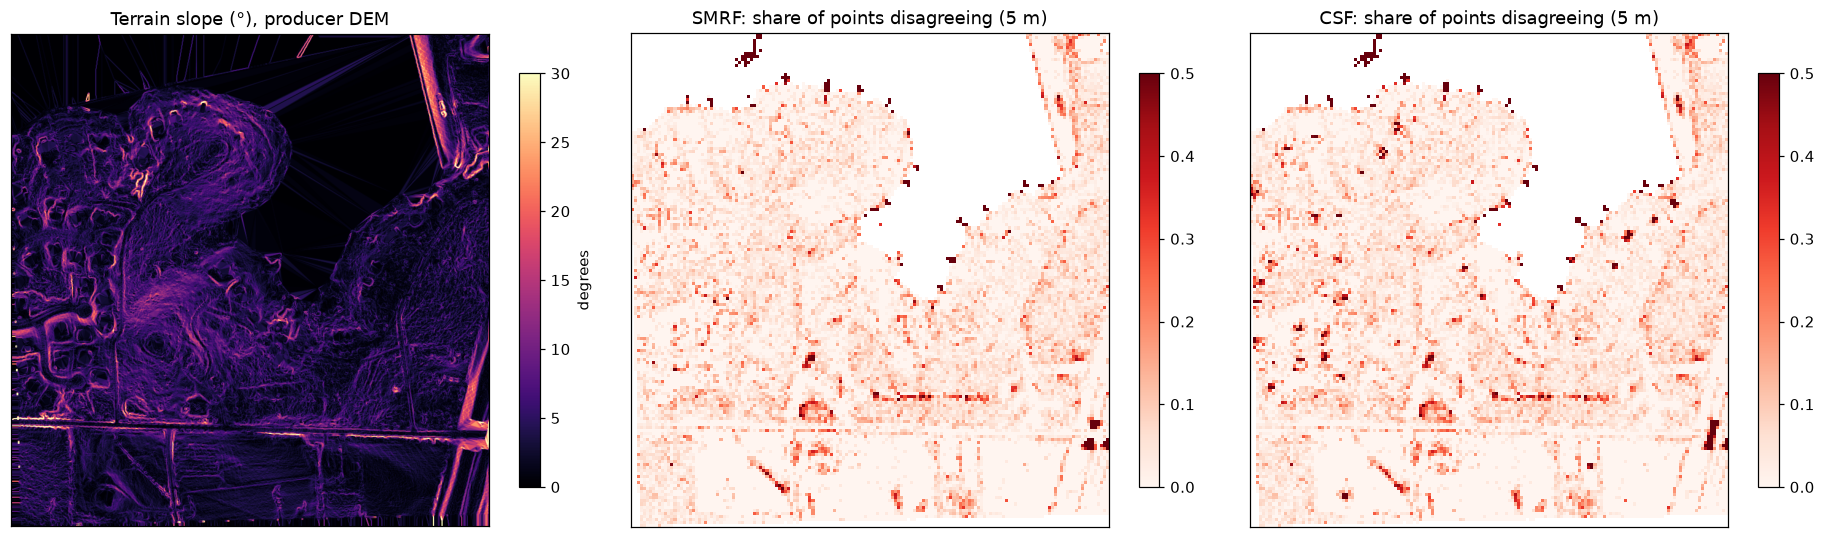

In [15]:
c_ref = np.asarray(mad["classification"])  # producer classes
valid = np.isin(c_ref, (2, 3, 4))  # unambiguous points
fig, axes = plt.subplots(1, 3, figsize=(17, 5))  # three panels
dem_ref = rs.lidar.dem(mad, 1.0)  # producer DEM for context
rs.viz.plot_raster(rs.lidar.slope(dem_ref), ax=axes[0], cmap="magma", vmax=30, title="Terrain slope (°), producer DEM")  # slope
for ax, name in zip(axes[1:], ("SMRF", "CSF")):  # the two filters
    pred = np.asarray(ground[("Madison", name)]["classification"]) == 2  # predicted ground
    wrong = mad.filter(valid & (pred != (c_ref == 2)))  # points where filter and producer disagree
    err = rs.lidar.rasterize(wrong, 5.0, stat="count", bounds=mad.bbox) / rs.lidar.rasterize(  # disagreement share
        mad.filter(valid), 5.0, stat="count", bounds=mad.bbox)
    rs.viz.plot_raster(err, ax=ax, cmap="Reds", vmin=0, vmax=0.5, title=f"{name}: share of points disagreeing (5 m)")  # map
for a in axes: a.set_xticks([]); a.set_yticks([])  # no ticks
plt.tight_layout(); plt.show()  # draw

## Tuning the ground filters

The most important SMRF parameter is the **window**, the largest object the filter can remove. On the UB campus the widest buildings are well over 50 m across, so an 18 m window leaves their roofs in the ground class. The sweep below runs SMRF on a 2 m grid with windows from 10 m to 80 m and CSF with the three rigidness settings and scores each run against the producer's labels.


In [16]:
c_ub = np.asarray(ub["classification"])  # producer classes
valid_ub, ref_ub = np.isin(c_ub, (1, 2)), c_ub == 2  # unambiguous points and reference ground
rows = []  # one row per run
for w in (10, 18, 30, 50, 80):  # SMRF windows (m)
    t0 = time.perf_counter()  # start the timer
    pred = np.asarray(rs.lidar.smrf(ub, cell=2.0, slope=0.15, window=w)["classification"]) == 2  # classify on a 2 m grid
    rows.append({"filter": "SMRF", "setting": f"window {w} m", **scores(pred[valid_ub], ref_ub[valid_ub]),  # score
                 "seconds": time.perf_counter() - t0})
for rg in (1, 2, 3):  # CSF rigidness
    t0 = time.perf_counter()  # start the timer
    pred = np.asarray(rs.lidar.csf(ub, resolution=1.0, rigidness=rg)["classification"]) == 2  # classify
    rows.append({"filter": "CSF", "setting": f"rigidness {rg}", **scores(pred[valid_ub], ref_ub[valid_ub]),  # score
                 "seconds": time.perf_counter() - t0})
tune = pd.DataFrame(rows).set_index(["filter", "setting"]).round(3)  # as a table
tune  # show it

overall accuracy  kappa  ground recall  ground precision  \
filter setting                                                                 
SMRF   window 10 m             0.899  0.558          1.000             0.890   
       window 18 m             0.913  0.635          1.000             0.904   
       window 30 m             0.925  0.693          1.000             0.916   
       window 50 m             0.942  0.775          1.000             0.934   
       window 80 m             0.950  0.807          1.000             0.942   
CSF    rigidness 1             0.899  0.560          0.999             0.891   
       rigidness 2             0.914  0.641          0.999             0.906   
       rigidness 3             0.921  0.678          1.000             0.913   

                    seconds  
filter setting               
SMRF   window 10 m    0.215  
       window 18 m    0.629  
       window 30 m    2.886  
       window 50 m   12.438  
       window 80 m   47.939  
CSF    rigidness 1    7.214  
       rigidness 2   10.162  
       rigidness 3   11.958

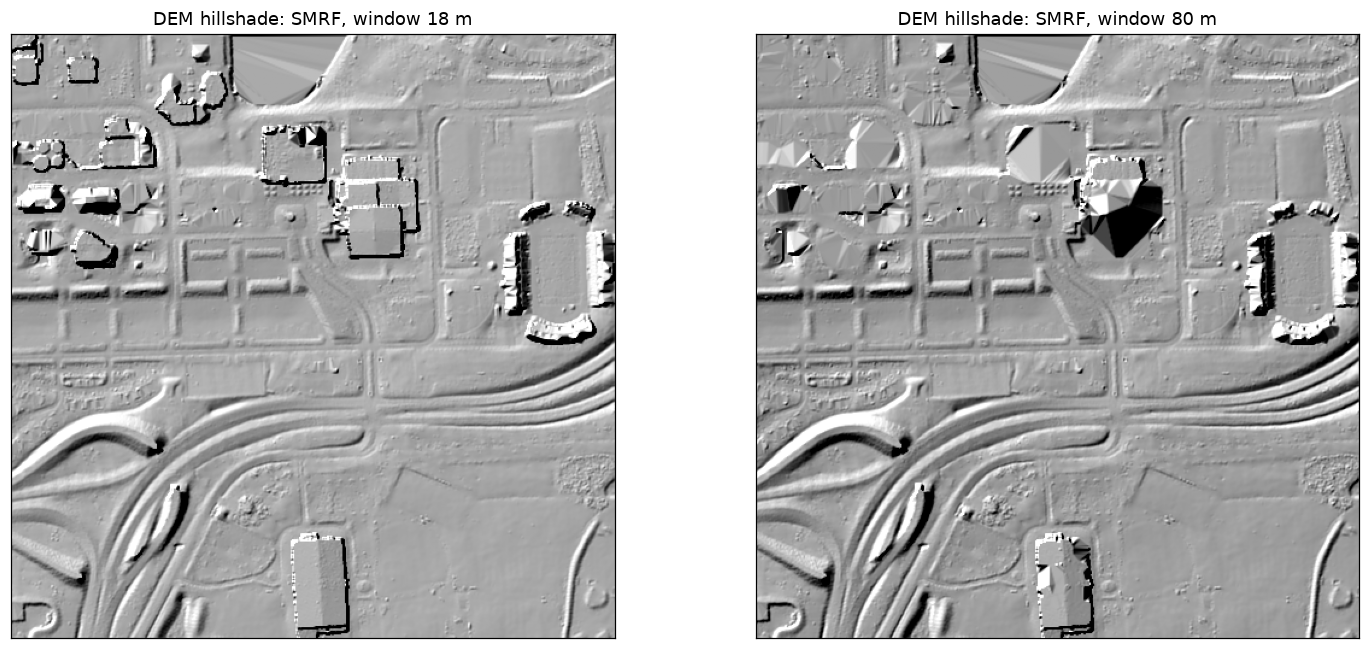

In [17]:
best_w = int(tune.loc["SMRF"]["kappa"].idxmax().split()[1])  # SMRF window with the highest kappa
ub_g = rs.lidar.smrf(ub, cell=2.0, slope=0.15, window=best_w)  # rerun with that window
fig, axes = plt.subplots(1, 2, figsize=(14, 6))  # two panels
for ax, (title, cloud) in zip(axes, ((f"SMRF, window 18 m", ground[("UB", "SMRF")]),  # default
                                     (f"SMRF, window {best_w} m", ub_g))):  # tuned
    dem_w = rs.lidar.dem(cloud, 2.0)  # DEM from that classification
    rs.viz.plot_raster(rs.lidar.hillshade(dem_w), ax=ax, cmap="gray", colorbar=False, title=f"DEM hillshade: {title}")  # relief
    ax.set_xticks([]); ax.set_yticks([])  # no ticks
plt.tight_layout(); plt.show()  # draw

The `seconds` column shows the price of large windows: the cost of a morphological opening grows with the window area, so SMRF slows down sharply beyond about 50 m, which is one reason to run it on a coarser grid (2 m here) or on tiles. Kappa rises steadily with the SMRF window, from 0.54 at 10 m to 0.80 at 80 m, the largest window tested; CSF improves with rigidness but stays below the wide-window SMRF (0.67). With the 18 m window the large campus buildings survive in the "ground" surface as flat-topped blocks. With the 80 m window most of them are removed, but triangular facets remain inside the largest footprints: a few roof or wall points are still labelled ground, and the linear interpolation spans the gap between them and the surrounding terrain. The stadium stands, built into an embankment, remain in both versions. Windows larger than 80 m would remove more roofs but cost much more time and start to cut off real terrain such as hilltops and road embankments.


## DEM, DSM and CHM

With ground classified, `rs.lidar.dem`, `rs.lidar.dsm` and `rs.lidar.chm` build the three surfaces on a common grid. `chm(dsm, dem)` subtracts the terrain and removes single-cell pits with a median filter.


DEM, DSM and CHM at 1 m in 5.4 s; grid (801, 779)


CSF DEM vs producer DEM: mean +0.13 m, RMSE 0.59 m, |difference| > 0.5 m in 4.7% of cells


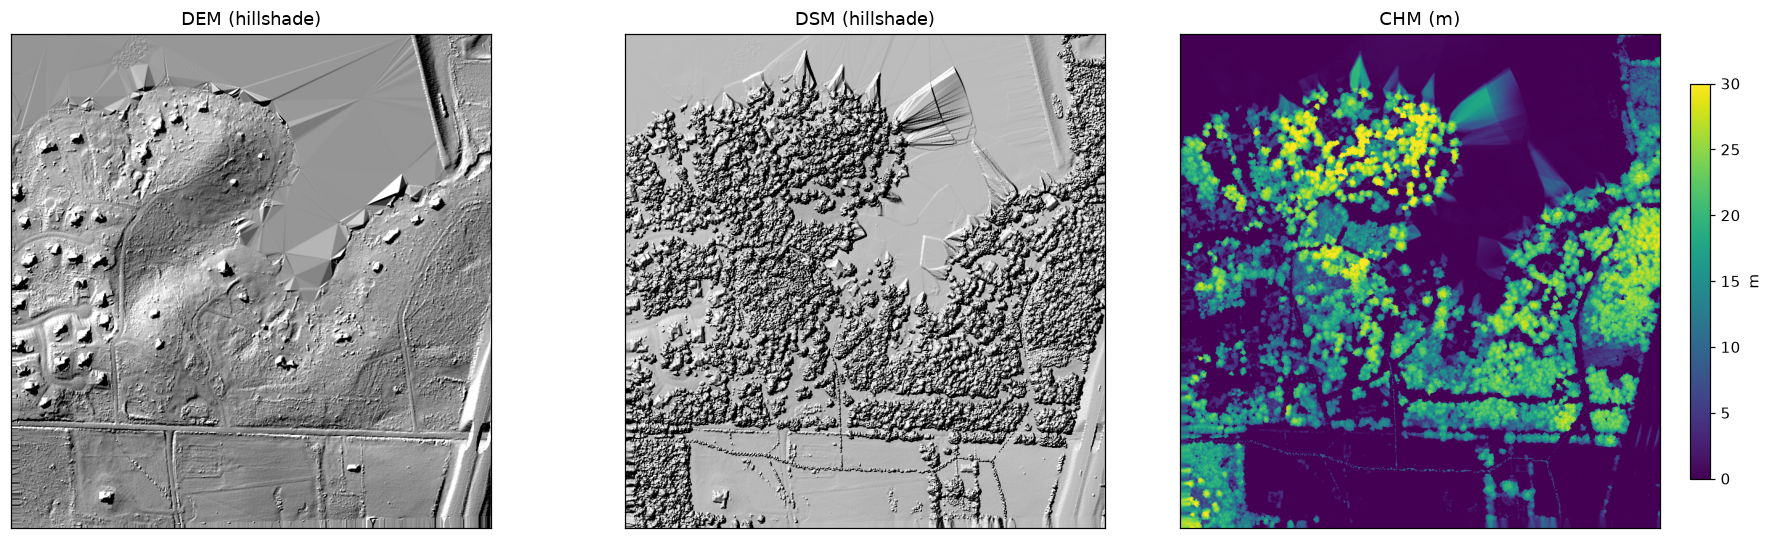

In [18]:
mad_g = ground[("Madison", "CSF")]  # Madison classified by CSF
t0 = time.perf_counter()  # start the timer
dem = rs.lidar.dem(mad_g, 1.0)  # bare-earth DEM, 1 m, gaps interpolated linearly
dsm = rs.lidar.dsm(mad_g, 1.0, bounds=mad_g.bbox).reindex_like(dem, method="nearest")  # first-return DSM on the same grid
chm = rs.lidar.chm(dsm, dem)  # canopy height model with pits removed
print(f"DEM, DSM and CHM at 1 m in {time.perf_counter() - t0:.1f} s; grid {dem.shape}")  # timing and size

dem_prod = rs.lidar.dem(mad, 1.0)  # DEM from the producer's ground points
d = dem - dem_prod.values  # CSF DEM minus producer DEM
# summary line
print(f"CSF DEM vs producer DEM: mean {float(d.mean()):+.2f} m, RMSE {float(np.sqrt((d ** 2).mean())):.2f} m, "
      f"|difference| > 0.5 m in {float((abs(d) > 0.5).mean()):.1%} of cells")  # agreement

fig, axes = plt.subplots(1, 3, figsize=(17, 5))  # three panels
rs.viz.plot_raster(rs.lidar.hillshade(dem), ax=axes[0], cmap="gray", colorbar=False, title="DEM (hillshade)")  # terrain
rs.viz.plot_raster(rs.lidar.hillshade(dsm), ax=axes[1], cmap="gray", colorbar=False, title="DSM (hillshade)")  # surface
rs.viz.plot_raster(chm, ax=axes[2], cmap="viridis", vmin=0, vmax=30, title="CHM (m)")  # canopy height
for a in axes: a.set_xticks([]); a.set_yticks([])  # no ticks
plt.tight_layout(); plt.show()  # draw

For UB the same steps give a normalised DSM (nDSM): buildings and trees as heights above the campus terrain. Its histogram already separates low objects (cars, shrubs) from buildings and trees.


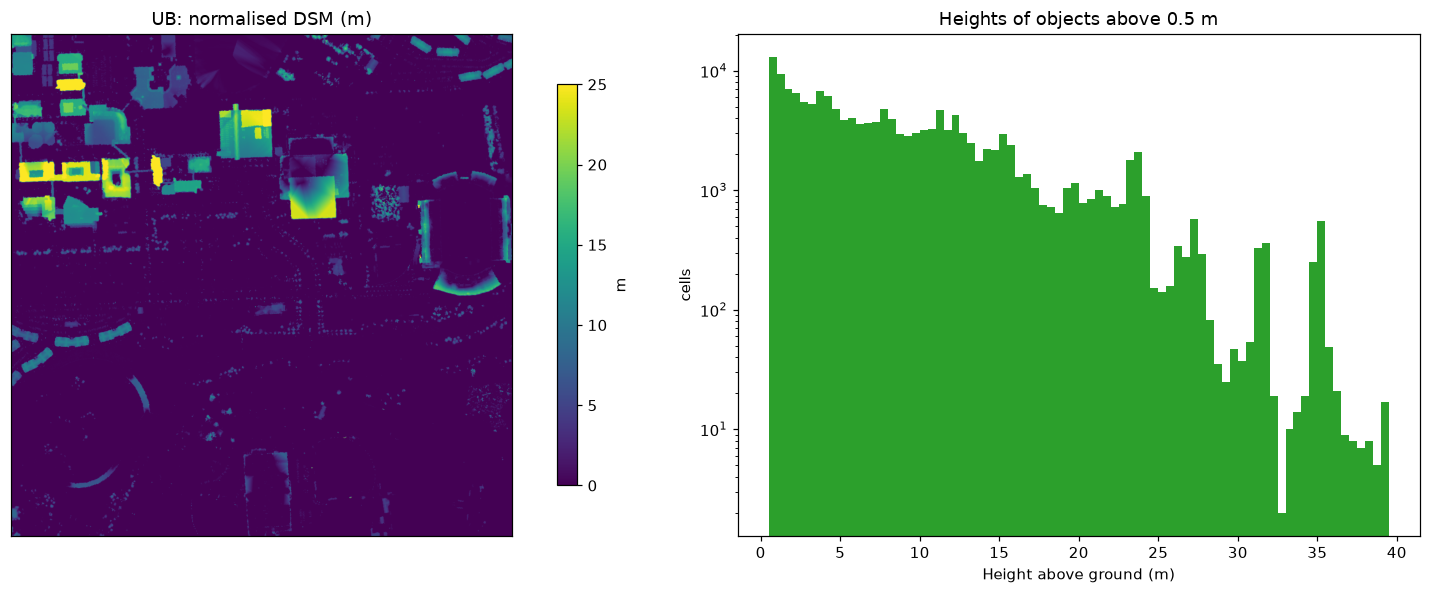

In [19]:
ub_dem = rs.lidar.dem(ub_g, 1.0)  # DEM from the tuned SMRF classification
ub_dsm = rs.lidar.dsm(ub_g, 1.0, bounds=ub_g.bbox).reindex_like(ub_dem, method="nearest")  # DSM on the same grid
ub_ndsm = rs.lidar.chm(ub_dsm, ub_dem)  # normalised DSM (height of objects)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.3, 1]})  # two panels
rs.viz.plot_raster(ub_ndsm, ax=axes[0], cmap="viridis", vmin=0, vmax=25, title="UB: normalised DSM (m)")  # map
axes[0].set_xticks([]); axes[0].set_yticks([])  # no ticks
v = ub_ndsm.values[np.isfinite(ub_ndsm.values)]  # all heights
axes[1].hist(v[v > 0.5], bins=np.arange(0.5, 40, 0.5), color="C2")  # heights above 0.5 m
axes[1].set(xlabel="Height above ground (m)", ylabel="cells", yscale="log", title="Heights of objects above 0.5 m")  # labels
plt.tight_layout(); plt.show()  # draw

## Gap filling and cell size

Under dense canopy and over water, many DEM cells contain no ground points at all. `rs.lidar.rasterize` with `stat="mean"` leaves them empty (NaN), and `rs.lidar.fill_gaps` fills them by nearest neighbour, inverse distance weighting or linear interpolation on a triangulation. The share of empty cells depends strongly on the cell size, which is why DEMs are often built at a coarser resolution than DSMs.


,empty DEM cells,empty DSM cells
0.5 m,0.799,0.767
1.0 m,0.412,0.342
2.0 m,0.273,0.232
5.0 m,0.226,0.219


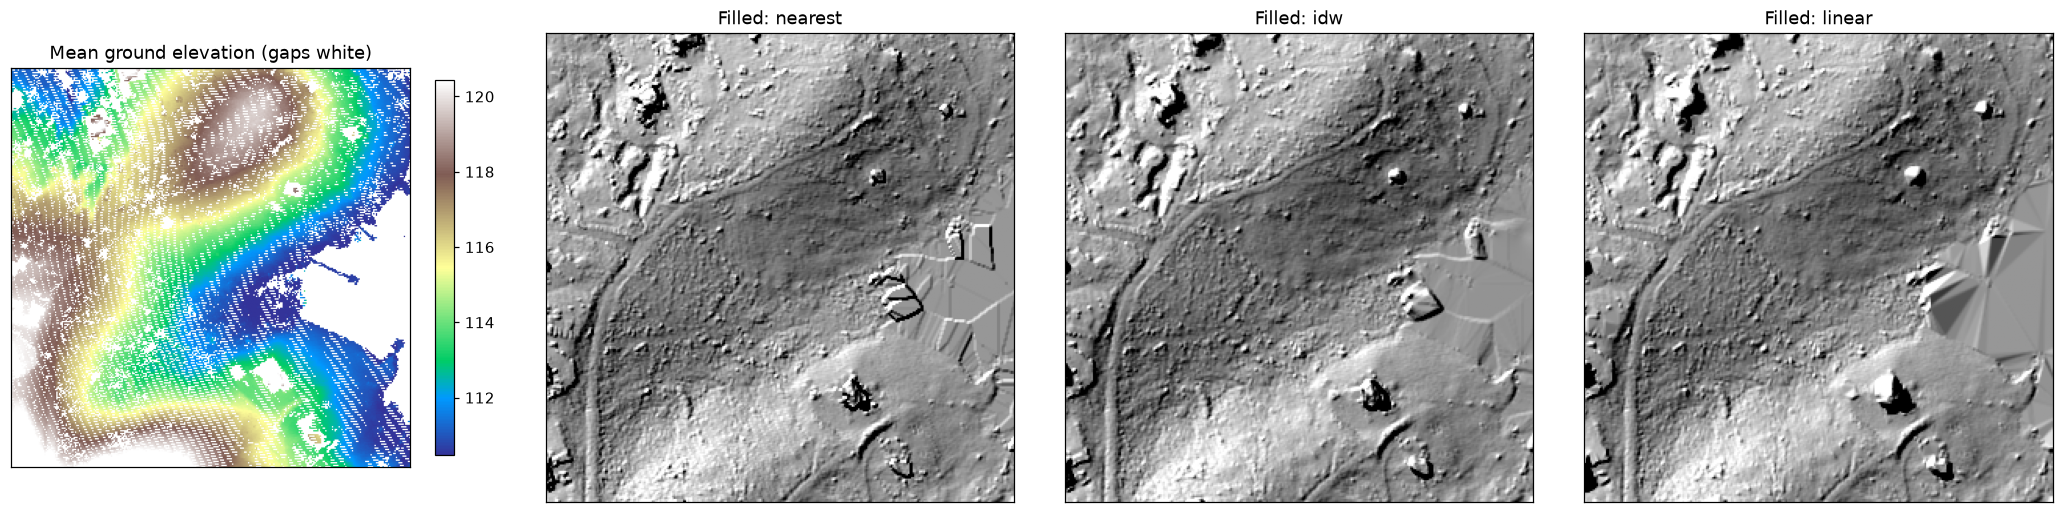

In [20]:
rows = {}  # one row per cell size
for res in (0.5, 1.0, 2.0, 5.0):  # cell sizes (m)
    raw = rs.lidar.rasterize(mad_g.ground(), res, stat="mean", bounds=mad_g.bbox)  # mean ground elevation per cell
    rows[f"{res} m"] = {"empty DEM cells": float(raw.isnull().mean()),  # share without ground points
                        "empty DSM cells": float(rs.lidar.rasterize(mad_g.first_returns(), res, stat="max",
                                                                      bounds=mad_g.bbox).isnull().mean())}
display(pd.DataFrame(rows).T.round(3))  # show the table

raw = rs.lidar.rasterize(mad_g.ground(), 1.0, stat="mean", bounds=mad_g.bbox)  # 1 m DEM with gaps
fills = {m: rs.lidar.fill_gaps(raw, m) for m in ("nearest", "idw", "linear")}  # three fills
win = dict(x=slice(150, 450), y=slice(150, 450))  # a 300 m window
fig, axes = plt.subplots(1, 4, figsize=(19, 4.6))  # four panels
rs.viz.plot_raster(raw.isel(win), ax=axes[0], cmap="terrain", title="Mean ground elevation (gaps white)")  # raw grid
for ax, (m, g) in zip(axes[1:], fills.items()):  # each fill
    rs.viz.plot_raster(rs.lidar.hillshade(g).isel(win), ax=ax, cmap="gray", colorbar=False, title=f"Filled: {m}")  # relief
for a in axes: a.set_xticks([]); a.set_yticks([])  # no ticks
plt.tight_layout(); plt.show()  # draw

At 1 m almost half of the cells in this forest have no ground point. Nearest-neighbour filling produces terraces, IDW gives dimpled surfaces around isolated points, and linear (TIN) interpolation gives the smoothest, most natural terrain. That is why `rs.lidar.dem` uses linear interpolation by default.


## Vertical accuracy with checkpoints

A DEM is tested against **checkpoints**: points whose elevation was surveyed independently, typically with RTK GNSS, on open and flat ground. Here 300 checkpoints are simulated by holding out producer ground points on flat, open terrain (slope < 3°, no canopy within 5 m). The DEM is rebuilt without them and compared with `rs.lidar.vertical_accuracy`, which reports RMSEz, the mean error and NVA₉₅ = 1.96 × RMSEz.


In [21]:
rng = np.random.default_rng(42)  # reproducible sampling
slope1 = rs.lidar.slope(dem_prod)  # slope of the producer DEM
open_cells = (slope1 < 3) & (chm.reindex_like(slope1, method="nearest") < 0.5)  # flat cells without canopy
g = mad.ground()  # producer ground points
gs = rs.lidar.sample_raster(g, open_cells.astype("float32"), "open")  # flag points in open flat cells
cand = np.flatnonzero(np.asarray(gs["open"]) == 1)  # candidate checkpoint indices
pick = rng.choice(cand, 300, replace=False)  # 300 checkpoints
is_cp = np.zeros(len(g), bool); is_cp[pick] = True  # mask of checkpoints
cps = gpd.GeoDataFrame({"z": np.asarray(g.z)[is_cp]},  # checkpoint elevations
                       geometry=gpd.points_from_xy(np.asarray(g.x)[is_cp], np.asarray(g.y)[is_cp]), crs=32615)

rest = mad.filter(~np.isin(np.arange(len(mad)), np.flatnonzero(np.asarray(mad["classification"]) == 2)[pick]))  # withhold them
rows = {}  # one row per DEM
for name, cloud in (("producer ground", rest), ("CSF ground", rs.lidar.csf(rest, resolution=1.0, rigidness=2))):  # DEMs
    for res in (1.0, 2.0):  # two cell sizes
        va = rs.lidar.vertical_accuracy(rs.lidar.dem(cloud, res), cps)  # compare with checkpoints
        # accuracy of this DEM
        rows[(name, f"{res} m")] = {"n": va["n"], "mean error (m)": va["mean_error"], "RMSEz (m)": va["rmse_z"],
                                     "NVA95 (m)": va["nva_95"]}  # results
pd.DataFrame(rows).T.round(3)  # show the table

n  mean error (m)  RMSEz (m)  NVA95 (m)
producer ground 1.0 m  300.0          -0.003      0.036      0.070
                2.0 m  300.0          -0.002      0.035      0.069
CSF ground      1.0 m  300.0           0.005      0.045      0.087
                2.0 m  300.0           0.007      0.048      0.095

The withheld checkpoints are matched with an RMSEz of 4 to 5 cm and no bias, well inside the 3DEP QL2 limit for non-vegetated vertical accuracy (RMSEz ≤ 10 cm, NVA₉₅ ≤ 19.6 cm). The CSF ground classification is about 1 cm worse than the producer's on open ground, and the 1 m and 2 m DEMs perform almost equally on flat terrain. Note that these checkpoints come from the LiDAR itself, so they test the gridding and interpolation, not the absolute georeferencing of the survey; a real assessment needs surveyed checkpoints.


## Exporting the products

`rs.write` writes rasters as Cloud-Optimized GeoTIFFs; `rs.lidar.write_las` writes the classified point cloud as LAZ with the new class codes.


In [22]:
products = {"madison_dem_1m.tif": dem, "madison_dsm_1m.tif": dsm, "madison_chm_1m.tif": chm,  # Madison rasters
            "ub_dem_1m.tif": ub_dem, "ub_ndsm_1m.tif": ub_ndsm}  # UB rasters
for name, da in products.items():  # each raster
    rs.write(da.astype("float32"), OUT / name)  # Cloud-Optimized GeoTIFF
rs.lidar.write_las(ub_g, OUT / "ub_ground_smrf.laz")  # UB with the tuned SMRF classes
for p in sorted(OUT.glob("madison_*_1m.tif")) + sorted(OUT.glob("ub_*")):  # list what was written
    print(f"{p.name:24s} {p.stat().st_size / 1e6:6.1f} MB")  # name and size

madison_chm_1m.tif          2.0 MB
madison_dem_1m.tif          1.9 MB
madison_dsm_1m.tif          2.1 MB
ub_buildings_classified.laz    3.7 MB
ub_dem_1m.tif               3.0 MB
ub_ground_smrf.laz          3.7 MB
ub_ndsm_1m.tif              2.4 MB


## Summary and exercises

**Key points**

- Check density (first returns per m²) against the specification and look at overlapping flight lines: on flat hard ground they should agree to about 10 cm.
- Statistical and radius outlier filters find isolated echoes, but in sparse data they also flag real walls, roof edges and poles; reclassify suspected noise instead of deleting it, and review it.
- Thin with the statistic the product needs: `grid_max` for a DSM, `grid_min` for a ground sample, voxels to keep 3D structure.
- SMRF, CSF and PMF all recover nearly all ground points; their errors concentrate on steep banks and under dense low vegetation. The SMRF window must exceed the widest building.
- DEM, DSM and CHM come from the same classified cloud. Linear (TIN) gap filling gives the most natural terrain under canopy; DEM cells should be coarser than DSM cells where ground points are sparse.
- Vertical accuracy is reported as RMSEz and NVA₉₅ against independent checkpoints on open ground.

**`geolattice.rsense` functions used:** `rs.lidar.read_las`, `rs.lidar.reproject`, `rs.lidar.merge_pointclouds`, `rs.lidar.summary`, `rs.lidar.density_map`, `rs.lidar.swath_overlap`, `rs.lidar.statistical_outlier_removal`, `rs.lidar.radius_outlier_removal`, `rs.lidar.clip_polygon`, `rs.lidar.thin`, `rs.lidar.classify_ground`, `rs.lidar.smrf`, `rs.lidar.csf`, `rs.lidar.pmf`, `rs.lidar.dem`, `rs.lidar.dsm`, `rs.lidar.chm`, `rs.lidar.rasterize`, `rs.lidar.fill_gaps`, `rs.lidar.normalize_heights`, `rs.lidar.sample_raster`, `rs.lidar.vertical_accuracy`, `rs.lidar.hillshade`, `rs.lidar.slope`, `rs.lidar.cross_section`, `rs.lidar.write_las`, `rs.write`, `rs.viz.plot_raster`.

**Exercises**

1. Repeat the swath-overlap test on Madison ground points. Do its flight lines agree as well as UB's?
2. Run SOR with `std_ratio` 2, 3 and 4 on UB. How many points are flagged, and how many of them are more than 40 m above ground?
3. Tune SMRF's `slope` (0.05 to 0.5) on Madison with the window fixed at 18 m. Which errors change?
4. Build the Madison DEM at 0.5, 1 and 2 m and repeat the checkpoint test. Does a finer DEM give a lower RMSEz?
5. Compute a CHM from the producer's ground and from CSF's ground and map their difference. Where does the ground filter matter most for canopy height?
